# 05 — Huấn luyện và so sánh mô hình

Huấn luyện LightGBM trên các cấu hình feature, đồng thời so sánh Linear Regression, Ridge và ExtraTrees trên cùng bộ feature `safe`. Các mô hình được so sánh với baseline B2c mean28 bằng NWRMSLE có trọng số trên hai fold thời gian.

Mỗi mô hình/fold có dự báo validation riêng. Notebook tạo biểu đồ so sánh điểm số, scatter thực tế–dự báo và residual plot thành **các hình độc lập** để có thể xem và đánh giá từng hình riêng.

Mỗi lần fit dùng mẫu train giới hạn để kiểm soát RAM. Điểm số chỉ phản ánh các fold validation đã định nghĩa; không thay thế đánh giá trên test holdout.

**Linear Regression** được sử dụng làm mô hình hồi quy tuyến tính cơ sở trong nhóm thực nghiệm, không thay thế baseline B2c mean28 đã xây dựng ở notebook 04.

In [22]:
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
import gc, json, hashlib, platform, time
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import psutil
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import ExtraTreesRegressor
try:
    import lightgbm as lgb
except ImportError as exc:
    raise ImportError('Cài lightgbm trong kernel hiện tại bằng %pip install lightgbm, rồi restart.') from exc

SEED = 42
BATCH_SIZE = 8192
MAX_TRAIN_ROWS = 120_000
MAX_INNER_VALID_ROWS = 20_000
NUM_BOOST_ROUND = 400
EARLY_STOPPING_ROUNDS = 40
TRAIN_ORIGIN_MIN = None  # Giữ mọi mốc hợp lệ rồi lấy mẫu đều theo dòng.
RUN_EXPERIMENTS = ['safe', 'plus_future_promo', 'plus_oil']
REFIT_FINAL_SAFE = True
SAVE_SAFE_VALID_PREDICTIONS = True
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')

def find_root():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / 'reports/03_config.json').is_file(): return p
    raise FileNotFoundError('Mở notebook bên trong project đã chạy 03 và 04.')
ROOT = find_root()
REPORT_DIR = ROOT / 'reports' / '05_runs' / RUN_ID
MODEL_DIR = ROOT / 'models' / '05_runs' / RUN_ID
PRED_DIR = ROOT / 'data' / 'interim' / '05_runs' / RUN_ID
for p in [REPORT_DIR, MODEL_DIR, PRED_DIR]: p.mkdir(parents=True, exist_ok=True)
CONFIG_PATH = ROOT / 'reports/03_config.json'
MANIFEST_PATH = ROOT / 'reports/table/03_feature_manifest.csv'
BASELINE_PATH = ROOT / 'reports/table/04_baselines.csv'
BASELINE_REPORT = ROOT / 'reports/04_baseline_report.json'
config = json.loads(CONFIG_PATH.read_text(encoding='utf-8'))
report04 = json.loads(BASELINE_REPORT.read_text(encoding='utf-8'))
HORIZON = int(config['horizon'])
FEATURE_DIR = ROOT / config['feature_dir'].replace('\\', '/')
manifest = pd.read_csv(MANIFEST_PATH, parse_dates=['origin'])
manifest['path'] = manifest.file.map(lambda x: FEATURE_DIR / Path(str(x)).name)
assert not manifest.duplicated(['role','origin']).any()
assert manifest.path.map(Path.is_file).all()
baseline04 = pd.read_csv(BASELINE_PATH)
folds = config['folds']
assert len(folds) >= 2

def digest(p): return hashlib.sha256(p.read_bytes()).hexdigest()
assert digest(CONFIG_PATH) == report04['source_config_sha256'], '03 config đổi: chạy lại 04.'
assert digest(MANIFEST_PATH) == report04['source_manifest_sha256'], '03 manifest đổi: chạy lại 04.'
print('LightGBM:', lgb.__version__, '| RAM khả dụng GiB:', round(psutil.virtual_memory().available/1024**3, 2))
print('Run:', RUN_ID, '| kết quả:', REPORT_DIR)


LightGBM: 4.7.0 | RAM khả dụng GiB: 2.82
Run: 20261029_225329 | kết quả: D:\Machine-learning-project-Grocery-sales-forecast\reports\05_runs\20261029_225329


## 1. Feature và tham số

| Cấu hình | Feature |
|---|---|
| `safe` | Lịch sử, lịch, metadata và phân cấp |
| `plus_future_promo` | Safe và khuyến mãi tương lai |
| `plus_oil` | Safe và giá dầu |

Các cấu hình dùng cùng cách lấy mẫu và tham số. Cột category được khai báo riêng; id, ngày mốc, nhãn và trọng số không đưa vào feature. Bản safe được lưu làm model cuối mặc định.


In [23]:
all_features = list(dict.fromkeys(c for group in config['feature_groups'].values() for c in group))
future_promo = ['promo_t','promo_h_sum','item_promo_share_t','store_promo_share_t']
oil_cols = ['oil_T','oil_chg_28']
excluded = set(future_promo + oil_cols + ['has_history','promo_known_t'])
safe_features = [c for c in all_features if c not in excluded]
feature_sets = {'safe': safe_features,
                'plus_future_promo': safe_features + future_promo,
                'plus_oil': safe_features + oil_cols}
assert 'safe' in RUN_EXPERIMENTS and set(RUN_EXPERIMENTS) <= set(feature_sets)
CATEGORICAL = ['store_type','store_cluster','store_state','store_city',
               'item_family','item_class','pair_status']
PARAMS = dict(objective='regression', metric='None', learning_rate=.05,
    num_leaves=15, max_depth=-1, min_data_in_leaf=100, max_bin=63,
    lambda_l2=2.0, feature_fraction=1.0, bagging_fraction=1.0,
    num_threads=2, deterministic=True, force_col_wise=True,
    histogram_pool_size=32, seed=SEED, verbosity=-1)
for r in manifest.itertuples():
    pf = pq.ParquetFile(r.path)
    assert pf.metadata.num_rows == int(r.rows), f'{r.file}: số dòng khác manifest'
    for exp in RUN_EXPERIMENTS:
        assert set(feature_sets[exp]) <= set(pf.schema_arrow.names), f'{r.file}: thiếu feature'
print({e: len(feature_sets[e]) for e in RUN_EXPERIMENTS})


{'safe': 67, 'plus_future_promo': 71, 'plus_oil': 69}


## 2. Đọc mẫu train

Lấy mẫu đều theo dòng từ các mốc hợp lệ. Cùng seed cho các cấu hình trong một fold. Đây là lần lấy mẫu thêm từ dữ liệu 03.

Kiểm tra RAM chỉ là ước lượng. Nếu thiếu bộ nhớ, giảm số dòng và chạy lại với cùng cấu hình lấy mẫu khi so sánh.


In [24]:
def iter_frames(paths, columns):
    for path in paths:
        for b in pq.ParquetFile(path).iter_batches(batch_size=BATCH_SIZE, columns=columns):
            yield b.to_pandas()

def eligible_train(cut):
    tr = manifest[(manifest.role == 'train') &
        (manifest.origin + pd.Timedelta(days=HORIZON) <= cut)].sort_values('origin')
    if TRAIN_ORIGIN_MIN is not None: tr = tr[tr.origin >= pd.Timestamp(TRAIN_ORIGIN_MIN)]
    assert len(tr), f'Không có train trước {cut}'
    return tr

def memory_guard(n, p):
    # Phần dư cho Arrow/pandas, histogram và các mảng tạm; đây chỉ là ước lượng.
    estimate = n * (p + 2) * 4 * 5 + 160 * 1024**2
    available = psutil.virtual_memory().available
    if estimate > available * .8:
        raise MemoryError(f'Ước cần {estimate/1024**2:.0f} MiB, còn {available/1024**2:.0f} MiB. '
                          'Đóng ứng dụng/kernel khác hoặc giảm MAX_TRAIN_ROWS.')

def matrix(d, features):
    x = d[features].to_numpy(dtype=np.float32, copy=True)
    if np.isinf(x).any(): raise ValueError('Feature chứa infinity; kiểm tra 03.')
    for c in CATEGORICAL:
        if c in features:
            a = x[:, features.index(c)]; a = a[np.isfinite(a)]
            assert ((a >= 0) & (a == np.floor(a)) & (a < 2**24)).all(), f'Mã category lỗi: {c}'
    return x

def load_sample(rows, features, cap, seed, cutoff):
    total = int(rows.rows.sum()); n = min(total, int(cap))
    assert n > 0
    memory_guard(n, len(features))
    chosen = np.sort(np.random.default_rng(seed).choice(total, n, replace=False))
    x = np.empty((n, len(features)), dtype=np.float32)
    y = np.empty(n, dtype=np.float32); w = np.empty(n, dtype=np.float32)
    start = dest = 0
    cols = list(dict.fromkeys(features + ['y_log','w','perishable','origin','date','pair_status']))
    for d in iter_frames(rows.path, cols):
        end = start + len(d)
        lo, hi = np.searchsorted(chosen, [start, end])
        if hi > lo:
            sub = d.iloc[chosen[lo:hi]-start]
            assert (sub.date <= cutoff).all(), 'Nhãn vượt cutoff'
            assert (sub.origin + pd.Timedelta(days=HORIZON) <= cutoff).all()
            assert (sub.date-sub.origin).dt.days.between(1,HORIZON).all()
            assert sub.pair_status.isin([0,1]).all(), 'Mô hình chính chỉ học status 0/1.'
            k = len(sub)
            x[dest:dest+k] = matrix(sub, features)
            y[dest:dest+k] = sub.y_log
            w[dest:dest+k] = sub.w
            assert np.allclose(sub.w, np.where(sub.perishable == 1,1.25,1.0))
            dest += k
        start = end
    assert dest == n and start == total
    assert np.isfinite(y).all() and (y >= 0).all()
    assert np.isfinite(w).all() and (w > 0).all()
    return x, y, w

def metric(pred, dataset):
    y = dataset.get_label(); w = dataset.get_weight()
    return 'NWRMSLE', float(np.sqrt(np.average((np.maximum(pred,0)-y)**2, weights=w))), False

def dataset_for(x,y,w,features,reference=None):
    return lgb.Dataset(x, label=y, weight=w, feature_name=features,
        categorical_feature=[c for c in CATEGORICAL if c in features],
        reference=reference, free_raw_data=True)


## 3. Chọn số vòng huấn luyện

Dùng mốc train hợp lệ cuối cùng làm kiểm định nội bộ. Train nội bộ chỉ có nhãn kết thúc trước hoặc tại mốc đó.

Sau khi chọn số vòng, fit lại từ đầu trên mẫu train hợp lệ của fold ngoài. V1/V2 dùng để chấm và so sánh, không dùng trực tiếp cho early stopping.


In [25]:
def fit_fold(cut, features, seed):
    tr = eligible_train(cut)
    inner_origin = tr.origin.max()
    inner_va = tr[tr.origin == inner_origin]
    inner_tr = tr[tr.origin + pd.Timedelta(days=HORIZON) <= inner_origin]
    assert len(inner_tr), 'Cửa sổ train quá ngắn cho kiểm định nội bộ có purge.'
    x,y,w = load_sample(inner_tr,features,MAX_TRAIN_ROWS,seed,inner_origin)
    xv,yv,wv = load_sample(inner_va,features,MAX_INNER_VALID_ROWS,seed+1,cut)
    train_ds = dataset_for(x,y,w,features)
    valid_ds = dataset_for(xv,yv,wv,features,train_ds)
    history = {}
    temp = lgb.train(PARAMS,train_ds,num_boost_round=NUM_BOOST_ROUND,
        valid_sets=[valid_ds],valid_names=['inner'],feval=metric,
        callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS,first_metric_only=True,verbose=False),
                   lgb.record_evaluation(history)])
    rounds = int(temp.best_iteration or NUM_BOOST_ROUND)
    info = dict(inner_origin=str(inner_origin.date()), inner_train_origins=len(inner_tr),
        inner_train_rows=len(y), inner_valid_rows=len(yv), best_iteration=rounds,
        inner_best_score=float(temp.best_score['inner']['NWRMSLE']))
    del temp,train_ds,valid_ds,x,y,w,xv,yv,wv; gc.collect()
    x,y,w = load_sample(tr,features,MAX_TRAIN_ROWS,seed,cut)
    info.update(train_origins=len(tr), eligible_train_rows=int(tr.rows.sum()),
                sampled_train_rows=len(y), sample_constant_log=float(np.average(y,weights=w)))
    train_ds = dataset_for(x,y,w,features)
    model = lgb.train(PARAMS,train_ds,num_boost_round=rounds)
    model.free_dataset()
    del train_ds,x,y,w; gc.collect()
    return model,info,history


## 4. Chấm validation

Tính model và B2c trên cùng dòng, cùng trọng số. Đọc theo batch và cộng sai số trước khi lấy căn. Lưu dự báo safe cùng khóa, nhãn và nhóm để phân tích ở 06.


In [26]:
def score_fold(model,features,fold,exp):
    cut = pd.Timestamp(fold['valid_origin'])
    va = manifest[(manifest.role == fold['valid_role']) & (manifest.origin == cut)]
    assert len(va) == 1
    cols = list(dict.fromkeys(features+['y_log','w','mean_28','pair_status','perishable',
                          'h','item_family','origin','date','store_nbr','item_nbr']))
    acc = defaultdict(lambda:[0,0.,0.])
    pred_path = PRED_DIR / f"{fold['fold']}_{exp}.parquet"
    writer = None
    try:
        for d in iter_frames(va.path,cols):
            assert (d.origin == cut).all() and ((d.date-d.origin).dt.days == d.h).all()
            assert d.h.between(1,HORIZON).all() and d.pair_status.isin([0,1]).all()
            y = d.y_log.to_numpy(dtype=np.float64); w = d.w.to_numpy(dtype=np.float64)
            assert np.isfinite(y).all() and (y>=0).all()
            assert np.isfinite(w).all() and (w>0).all()
            assert np.allclose(w,np.where(d.perishable==1,1.25,1.0))
            pred = np.maximum(model.predict(matrix(d,features),num_threads=2),0.)
            baseline = np.maximum(d.mean_28.fillna(0).to_numpy(dtype=np.float64),0.)
            assert np.isfinite(pred).all() and np.isfinite(baseline).all()
            groups=[('overall','all',np.ones(len(d),dtype=bool))]
            for group in ['pair_status','perishable','h','item_family']:
                for v in sorted(d[group].unique()):
                    groups.append((group,str(int(v)),d[group].to_numpy()==v))
            for name,p in [('model',pred),('B2c_mean28',baseline)]:
                for group,value,m in groups:
                    z=acc[(name,group,value)]; e=p[m]-y[m]
                    z[0]+=int(m.sum()); z[1]+=float(w[m].sum()); z[2]+=float(np.dot(w[m],e*e))
            if SAVE_SAFE_VALID_PREDICTIONS:
                saved=d[['store_nbr','item_nbr','origin','date','h','pair_status','perishable','item_family','y_log','w']].copy()
                saved['pred_log']=pred.astype('float32'); saved['baseline_log']=baseline.astype('float32')
                table=pa.Table.from_pandas(saved,preserve_index=False)
                if writer is None: writer=pq.ParquetWriter(pred_path.with_suffix('.tmp'),table.schema,compression='zstd')
                writer.write_table(table)
    finally:
        if writer is not None:writer.close()
    if writer is not None:pred_path.with_suffix('.tmp').replace(pred_path)
    rows=[]
    for (name,group,value),(n,sw,sse) in acc.items():
        assert sw>0
        rows.append(dict(fold=fold['fold'],experiment=exp,predictor=name,group=group,value=value,
                         rows=n,weight_sum=sw,weighted_sse=sse,NWRMSLE=float(np.sqrt(sse/sw))))
    result=pd.DataFrame(rows)
    assert (result.loc[result.group=='overall','rows']==int(va.rows.sum())).all()
    ref=baseline04[(baseline04.fold==fold['fold']) & (baseline04.baseline=='B2c_mean28')]
    assert len(ref)==1
    got=result[(result.group=='overall') & (result.predictor=='B2c_mean28')].NWRMSLE.iloc[0]
    assert np.isclose(got,ref.NWRMSLE.iloc[0],rtol=1e-6,atol=1e-8), 'Baseline khác 04: kiểm tra dữ liệu.'
    return result


## 5. Chạy các cấu hình

Chạy lần lượt từng fold để giảm RAM. Lưu model và kết quả sau mỗi lần chạy.


In [27]:
results=[]; runs=[]; importances=[]
for exp in RUN_EXPERIMENTS:
    features=feature_sets[exp]
    for fold in folds:
        t0=time.time(); cut=pd.Timestamp(fold['valid_origin'])
        seed=SEED+int(cut.strftime('%Y%m%d'))
        print('Đang chạy:',exp,fold['fold'],flush=True)
        model,info,history=fit_fold(cut,features,seed)
        model_path=MODEL_DIR / f"{exp}_{fold['fold']}.txt"
        model.save_model(str(model_path))
        r=score_fold(model,features,fold,exp)
        results.append(r)
        runs.append(dict(experiment=exp,fold=fold['fold'],features=features,
            model_path=str(model_path.relative_to(ROOT)),seconds=time.time()-t0,**info))
        (REPORT_DIR / f"{exp}_{fold['fold']}_learning_curve.json").write_text(json.dumps(history,indent=2))
        imp=pd.DataFrame({'feature':features,'gain':model.feature_importance(importance_type='gain'),
                          'split':model.feature_importance(importance_type='split')})
        imp['experiment']=exp;imp['fold']=fold['fold'];importances.append(imp)
        pd.concat(results,ignore_index=True).to_csv(REPORT_DIR/'scores.csv',index=False)
        (REPORT_DIR/'training_runs.json').write_text(json.dumps(runs,ensure_ascii=False,indent=2))
        display(r[r.group=='overall'][['fold','experiment','predictor','NWRMSLE']])
        del model;gc.collect()
results_df=pd.concat(results,ignore_index=True)
importance_df=pd.concat(importances,ignore_index=True)
importance_df.to_csv(REPORT_DIR/'feature_importance.csv',index=False)


Đang chạy: safe V1_last16


,fold,experiment,predictor,NWRMSLE
0,V1_last16,safe,model,0.614003
39,V1_last16,safe,B2c_mean28,0.638588


Đang chạy: safe V2_seasonal


,fold,experiment,predictor,NWRMSLE
0,V2_seasonal,safe,model,0.586527
38,V2_seasonal,safe,B2c_mean28,0.607533


Đang chạy: plus_future_promo V1_last16


...

,fold,experiment,predictor,NWRMSLE
0,V2_seasonal,plus_future_promo,model,0.571574
38,V2_seasonal,plus_future_promo,B2c_mean28,0.607533


Đang chạy: plus_oil V1_last16


,fold,experiment,predictor,NWRMSLE
0,V1_last16,plus_oil,model,0.614332
39,V1_last16,plus_oil,B2c_mean28,0.638588


Đang chạy: plus_oil V2_seasonal


,fold,experiment,predictor,NWRMSLE
0,V2_seasonal,plus_oil,model,0.586539
38,V2_seasonal,plus_oil,B2c_mean28,0.607533


**Lý do lựa chọn mô hình:** Linear Regression cung cấp mốc so sánh tuyến tính cơ bản; Ridge giúp khảo sát tác động của regularization L2; ExtraTrees khảo sát khả năng mô hình hóa quan hệ phi tuyến. Các mô hình sử dụng cùng feature safe, fold validation và chỉ số NWRMSLE để so sánh với LightGBM.

In [28]:
# Linear Regression, Ridge và ExtraTrees trên cùng feature `safe`

# Hai mô hình sklearn được huấn luyện riêng vì không dùng early stopping của LightGBM.
# Cùng fold, cùng nhãn/weight và cùng metric NWRMSLE để so sánh công bằng.
from sklearn.base import clone

CLASSIC_TRAIN_CAP = min(MAX_TRAIN_ROWS, 80_000)
CLASSIC_MODELS = {
    'linear_safe': LinearRegression(),
    'ridge_safe': Ridge(alpha=10.0, solver='lsqr'),
    'extratrees_safe': ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=5, max_features=0.8,
        n_jobs=2, random_state=SEED
    )
}
classic_features = feature_sets['safe']
cat_cols = [c for c in CATEGORICAL if c in classic_features]
num_cols = [c for c in classic_features if c not in cat_cols]

def make_classic_pipeline(name):
    # Linear/Ridge cần one-hot cho biến phân loại; scale biến số để hệ số dễ ổn định.
    if name in ['linear_safe', 'ridge_safe']:
        numeric = Pipeline([
            ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('scale', StandardScaler())
        ])
        categorical = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ])
        prep = ColumnTransformer([
            ('num', numeric, num_cols),
            ('cat', categorical, cat_cols)
        ], sparse_threshold=1.0)
        return Pipeline([('prep', prep), ('model', clone(CLASSIC_MODELS[name]))])
    # ExtraTrees có thể xử lý quan hệ phi tuyến; mã category được giữ dạng số.
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('model', clone(CLASSIC_MODELS[name]))
    ])

def load_validation_frame(rows, features):
    cols = list(dict.fromkeys(features + ['y_log','w','mean_28','pair_status','perishable',
        'h','item_family','origin','date','store_nbr','item_nbr']))
    for d in iter_frames(rows.path, cols):
        yield d

def score_classic_fold(model, features, fold, exp):
    cut = pd.Timestamp(fold['valid_origin'])
    va = manifest[(manifest.role == fold['valid_role']) & (manifest.origin == cut)]
    assert len(va) == 1
    acc = defaultdict(lambda: [0, 0., 0.])
    pred_path = PRED_DIR / f"{fold['fold']}_{exp}.parquet"
    writer = None
    try:
        for d in load_validation_frame(va, features):
            assert (d.origin == cut).all()
            y = d.y_log.to_numpy(dtype=np.float64)
            w = d.w.to_numpy(dtype=np.float64)
            x = d[features]
            pred = np.maximum(model.predict(x), 0.)
            baseline = np.maximum(d.mean_28.fillna(0).to_numpy(dtype=np.float64), 0.)
            assert np.isfinite(pred).all() and np.isfinite(baseline).all()
            groups = [('overall','all',np.ones(len(d),dtype=bool))]
            for group in ['pair_status','perishable','h','item_family']:
                for v in sorted(d[group].unique()):
                    groups.append((group,str(int(v)),d[group].to_numpy()==v))
            for name,prediction in [('model',pred),('B2c_mean28',baseline)]:
                for group,value,mask in groups:
                    z = acc[(name,group,value)]
                    err = prediction[mask] - y[mask]
                    z[0] += int(mask.sum())
                    z[1] += float(w[mask].sum())
                    z[2] += float(np.dot(w[mask], err*err))
            if SAVE_SAFE_VALID_PREDICTIONS:
                saved = d[['store_nbr','item_nbr','origin','date','h','pair_status',
                    'perishable','item_family','y_log','w']].copy()
                saved['pred_log'] = pred.astype('float32')
                saved['baseline_log'] = baseline.astype('float32')
                table = pa.Table.from_pandas(saved, preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(pred_path.with_suffix('.tmp'), table.schema, compression='zstd')
                writer.write_table(table)
    finally:
        if writer is not None:
            writer.close()
    if writer is not None:
        pred_path.with_suffix('.tmp').replace(pred_path)
    rows_out = []
    for (predictor,group,value),(n,sw,sse) in acc.items():
        rows_out.append(dict(fold=fold['fold'],experiment=exp,predictor=predictor,
            group=group,value=value,rows=n,weight_sum=sw,weighted_sse=sse,
            NWRMSLE=float(np.sqrt(sse/sw))))
    result = pd.DataFrame(rows_out)
    ref = baseline04[(baseline04.fold==fold['fold']) & (baseline04.baseline=='B2c_mean28')]
    got = result[(result.group=='overall') & (result.predictor=='B2c_mean28')].NWRMSLE.iloc[0]
    assert len(ref)==1 and np.isclose(got,ref.NWRMSLE.iloc[0],rtol=1e-6,atol=1e-8)
    return result

classic_results, classic_runs = [], []
for exp in CLASSIC_MODELS:
    for fold in folds:
        t0 = time.time()
        cut = pd.Timestamp(fold['valid_origin'])
        tr = eligible_train(cut)
        x_train, y_train, w_train = load_sample(
            tr, classic_features, CLASSIC_TRAIN_CAP,
            SEED + int(cut.strftime('%Y%m%d')), cut
        )
        x_train_df = pd.DataFrame(x_train, columns=classic_features)
        model = make_classic_pipeline(exp)
        model.fit(x_train_df, y_train, model__sample_weight=w_train)
        del x_train, y_train, w_train, x_train_df
        gc.collect()
        result = score_classic_fold(model, classic_features, fold, exp)
        classic_results.append(result)
        classic_runs.append({
            'experiment': exp, 'fold': fold['fold'],
            'features': classic_features, 'sample_cap': CLASSIC_TRAIN_CAP,
            'seconds': time.time()-t0,
            'model_params': CLASSIC_MODELS[exp].get_params()
        })
        model_path = MODEL_DIR / f'{exp}_{fold["fold"]}.joblib'
        import joblib
        joblib.dump(model, model_path)
        print(exp, fold['fold'],
              result[(result.group=='overall') & (result.predictor=='model')][['NWRMSLE']].to_dict('records'))
        del model
        gc.collect()

if classic_results:
    results_df = pd.concat([results_df, *classic_results], ignore_index=True)
    results_df.to_csv(REPORT_DIR/'scores.csv', index=False)
    (REPORT_DIR/'classic_training_runs.json').write_text(
        json.dumps(classic_runs, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    summary = results_df[results_df.group=='overall'].pivot(
        index=['experiment','fold'], columns='predictor', values='NWRMSLE'
    ).reset_index()
    summary['improvement'] = summary['B2c_mean28'] - summary['model']
    summary['improvement_pct'] = 100*summary.improvement/summary['B2c_mean28']
    display(summary.round(6))
    summary.to_csv(REPORT_DIR/'comparison.csv', index=False)


linear_safe V1_last16 [{'NWRMSLE': 0.6197484073053391}]
linear_safe V2_seasonal [{'NWRMSLE': 0.5879398533963283}]
ridge_safe V1_last16 [{'NWRMSLE': 0.6192082134908731}]
ridge_safe V2_seasonal [{'NWRMSLE': 0.5876179574894933}]
extratrees_safe V1_last16 [{'NWRMSLE': 0.6136217571280189}]
extratrees_safe V2_seasonal [{'NWRMSLE': 0.5853080124630603}]


predictor,experiment,fold,B2c_mean28,model,improvement,improvement_pct
0,extratrees_safe,V1_last16,0.638588,0.613622,0.024966,3.909571
1,extratrees_safe,V2_seasonal,0.607533,0.585308,0.022225,3.658308
2,linear_safe,V1_last16,0.638588,0.619748,0.018839,2.950165
3,linear_safe,V2_seasonal,0.607533,0.587940,0.019594,3.225107
4,plus_future_promo,V1_last16,0.638588,0.591451,0.047137,7.381430
5,plus_future_promo,V2_seasonal,0.607533,0.571574,0.035959,5.918847
6,plus_oil,V1_last16,0.638588,0.614332,0.024256,3.798309
7,plus_oil,V2_seasonal,0.607533,0.586539,0.020994,3.455626
8,ridge_safe,V1_last16,0.638588,0.619208,0.019380,3.034757
9,ridge_safe,V2_seasonal,0.607533,0.587618,0.019915,3.278091


## 6. So sánh kết quả

`improvement = baseline − model`: số dương nghĩa là mô hình giảm lỗi so với B2c mean28. Các mô hình được chấm trên cùng fold, nhãn và trọng số.

- LightGBM chạy ba cấu hình feature: `safe`, `plus_future_promo`, `plus_oil`.
- Ridge và ExtraTrees dùng cùng bộ feature `safe`; do khác thuật toán, chúng được fit riêng bằng scikit-learn.
- Ridge dùng imputation + chuẩn hóa biến số + one-hot biến phân loại; ExtraTrees dùng imputation và mô hình cây tổ hợp.
- NWRMSLE thấp hơn là tốt hơn. Không kết luận mô hình tốt nhất trước khi xem bảng điểm thực tế.

Lưu ý: Ridge/ExtraTrees dùng mẫu train tối đa 80.000 dòng để giới hạn RAM/thời gian; LightGBM giữ cấu hình lấy mẫu ở trên. Đây là so sánh thực nghiệm trong giới hạn tài nguyên, không phải benchmark tối ưu toàn diện.


### Cách đọc kết quả

- **B2c mean28:** baseline đối chiếu.
- **LightGBM:** mô hình boosting; các cấu hình feature được báo cáo riêng.
- **Ridge:** hồi quy tuyến tính có regularization, với biến phân loại one-hot và biến số được chuẩn hóa.
- **ExtraTrees:** tổ hợp cây quyết định ngẫu nhiên, có thể học quan hệ phi tuyến.
- **NWRMSLE:** thấp hơn là tốt hơn. Cột improvement dương nghĩa là giảm lỗi so với baseline.


predictor,experiment,fold,B2c_mean28,model,improvement,improvement_pct
0,extratrees_safe,V1_last16,0.638588,0.613622,0.024966,3.909571
1,extratrees_safe,V2_seasonal,0.607533,0.585308,0.022225,3.658308
2,linear_safe,V1_last16,0.638588,0.619748,0.018839,2.950165
3,linear_safe,V2_seasonal,0.607533,0.587940,0.019594,3.225107
4,plus_future_promo,V1_last16,0.638588,0.591451,0.047137,7.381430
5,plus_future_promo,V2_seasonal,0.607533,0.571574,0.035959,5.918847
6,plus_oil,V1_last16,0.638588,0.614332,0.024256,3.798309
7,plus_oil,V2_seasonal,0.607533,0.586539,0.020994,3.455626
8,ridge_safe,V1_last16,0.638588,0.619208,0.019380,3.034757
9,ridge_safe,V2_seasonal,0.607533,0.587618,0.019915,3.278091


extratrees_safe : tốt hơn B2c trên cả hai fold
linear_safe : tốt hơn B2c trên cả hai fold
plus_future_promo : tốt hơn B2c trên cả hai fold
plus_oil : tốt hơn B2c trên cả hai fold
ridge_safe : tốt hơn B2c trên cả hai fold
safe : tốt hơn B2c trên cả hai fold


,fold,predictor,value,rows,NWRMSLE
1,V1_last16,model,0,2409184,0.655783
2,V1_last16,model,1,377056,0.202722
40,V1_last16,B2c_mean28,0,2409184,0.682718
41,V1_last16,B2c_mean28,1,377056,0.196470
109,V2_seasonal,model,0,1063198,0.611441
110,V2_seasonal,model,1,108932,0.241443
147,V2_seasonal,B2c_mean28,0,1063198,0.633751
148,V2_seasonal,B2c_mean28,1,108932,0.239932


,fold,predictor,value,rows,NWRMSLE
3,V1_last16,model,0,2154208,0.613252
4,V1_last16,model,1,632032,0.616047
42,V1_last16,B2c_mean28,0,2154208,0.637117
43,V1_last16,B2c_mean28,1,632032,0.642582
111,V2_seasonal,model,0,902848,0.586271
112,V2_seasonal,model,1,269282,0.587215
149,V2_seasonal,B2c_mean28,0,902848,0.605787
150,V2_seasonal,B2c_mean28,1,269282,0.612194


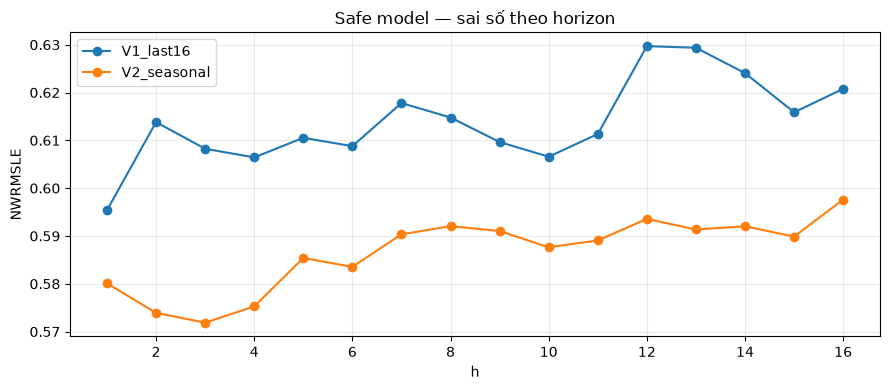

,gain
feature,
mean_14,415023.377538
mean_7,185799.245514
mean_28,162447.056373
dow_mean_8,129707.215082
dow_mean_16,51529.729220
meanpos_28,25375.449621
item_class,20901.733233
dow_mean_4,19451.128077
mean_3,18445.169534


In [29]:
summary=results_df[results_df.group=='overall'].pivot(
    index=['experiment','fold'],columns='predictor',values='NWRMSLE').reset_index()
summary['improvement']=summary['B2c_mean28']-summary['model']
summary['improvement_pct']=100*summary.improvement/summary['B2c_mean28']
display(summary.round(6))
summary.to_csv(REPORT_DIR/'comparison.csv',index=False)
for exp,g in summary.groupby('experiment'):
    print(exp,': tốt hơn B2c trên cả hai fold' if (g.improvement>0).all()
          else ': chưa tốt hơn B2c trên tất cả fold; xem từng fold.')
safe_scores=results_df[results_df.experiment=='safe']
for group in ['pair_status','perishable']:
    display(safe_scores[safe_scores.group==group][['fold','predictor','value','rows','NWRMSLE']])
fig,ax=plt.subplots(figsize=(9,4))
for fold in folds:
    d=safe_scores[(safe_scores.fold==fold['fold']) & (safe_scores.group=='h') &
                  (safe_scores.predictor=='model')].copy()
    d['h']=d.value.astype(int);d=d.sort_values('h')
    ax.plot(d.h,d.NWRMSLE,marker='o',label=fold['fold'])
ax.set(xlabel='h',ylabel='NWRMSLE',title='Safe model — sai số theo horizon')
ax.legend();ax.grid(alpha=.25);fig.tight_layout();plt.show()
display(importance_df[importance_df.experiment=='safe'].groupby('feature')['gain']
        .mean().sort_values(ascending=False).head(20).to_frame())


## 7. Thực tế, dự báo và sai số

Notebook tạo **một biểu đồ so sánh NWRMSLE**, sau đó tạo **hai hình riêng cho mỗi fold**: (1) thực tế–dự báo và (2) phần dư. Các điểm scatter lấy mẫu tối đa 5.000 dòng, còn điểm số NWRMSLE được tính trên toàn bộ validation. Trục dự báo dùng thang `log1p`. Mỗi hình được lưu thành file riêng trong thư mục run để dễ đánh giá và đưa vào báo cáo.


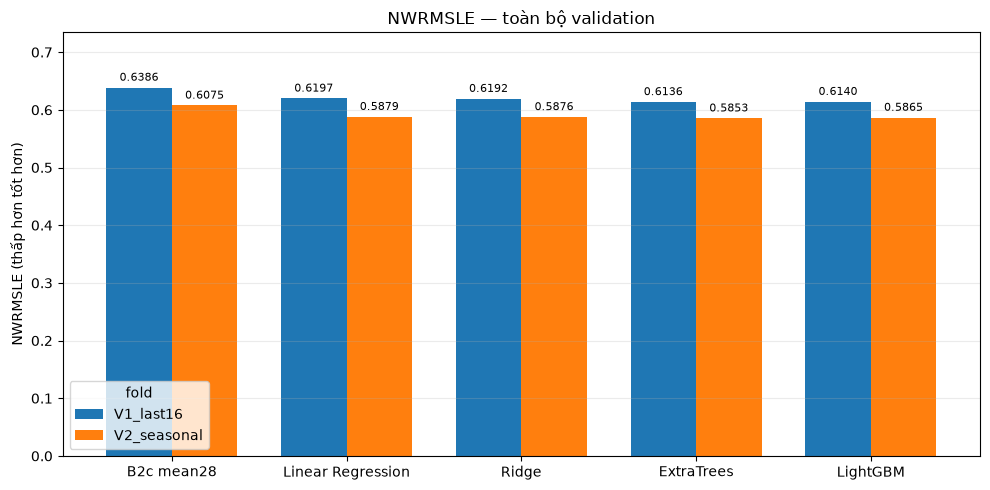

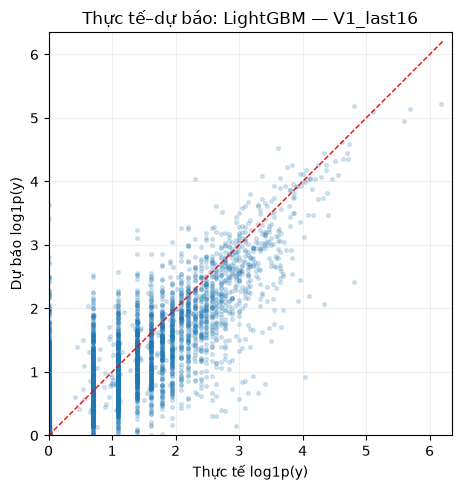

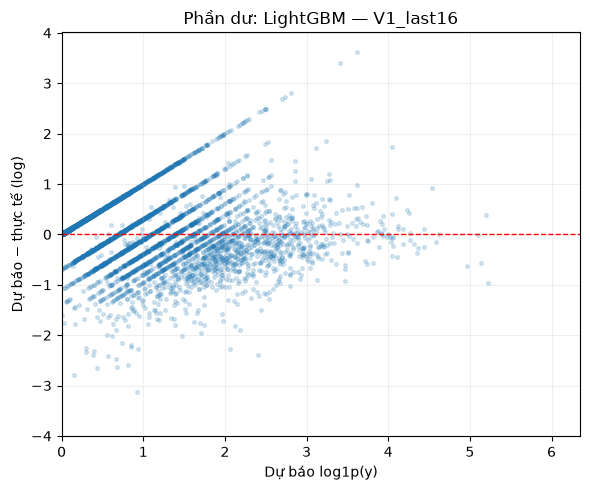

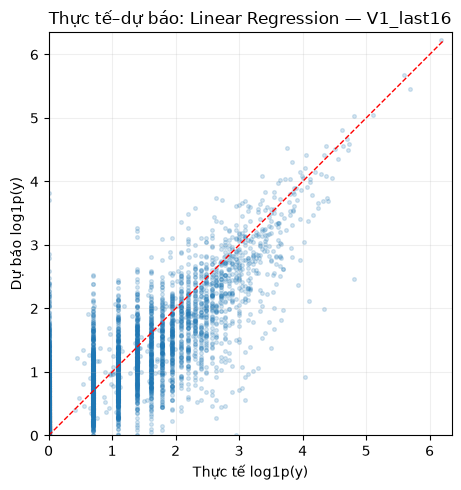

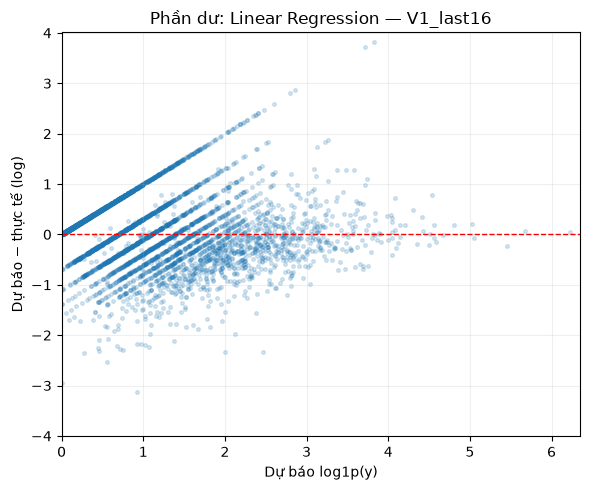

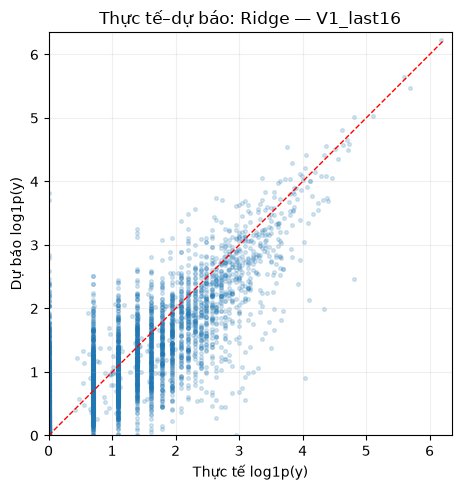

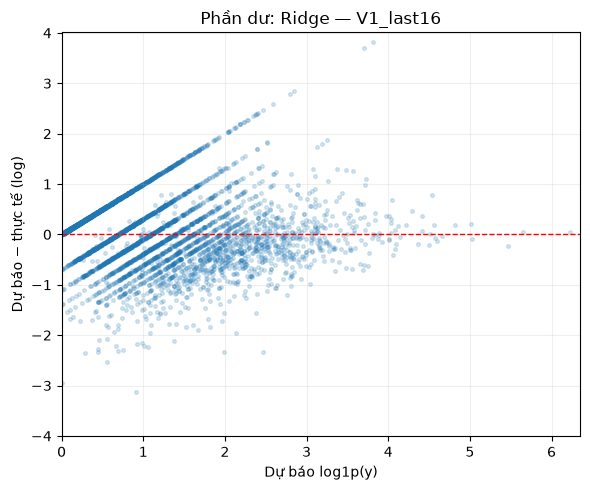

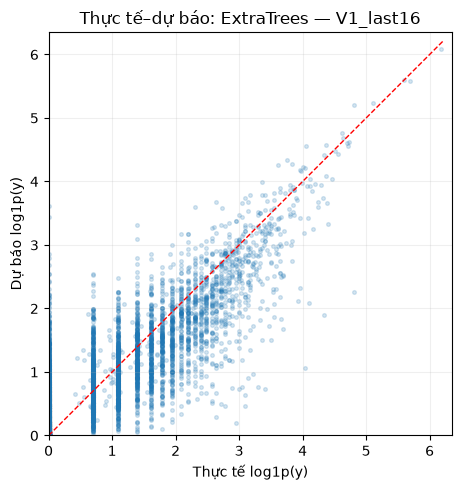

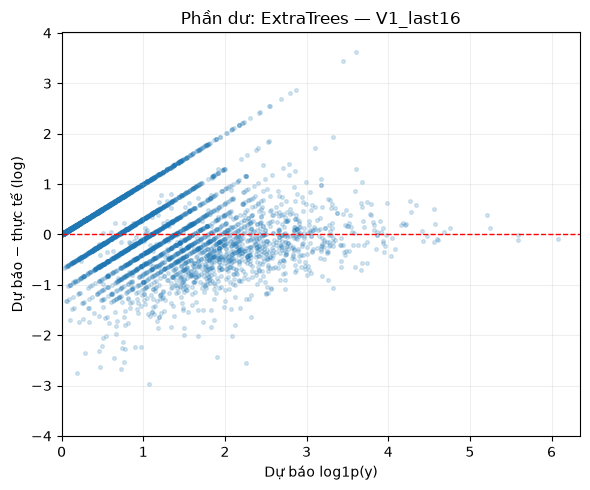

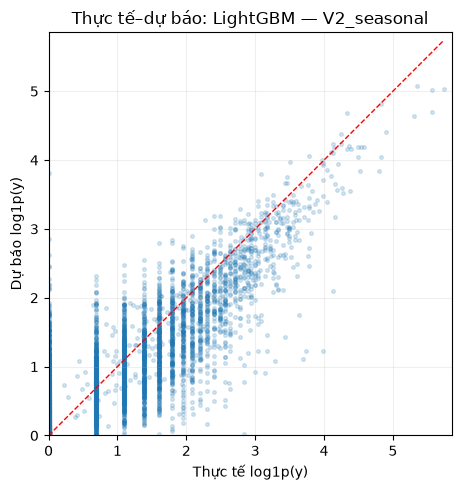

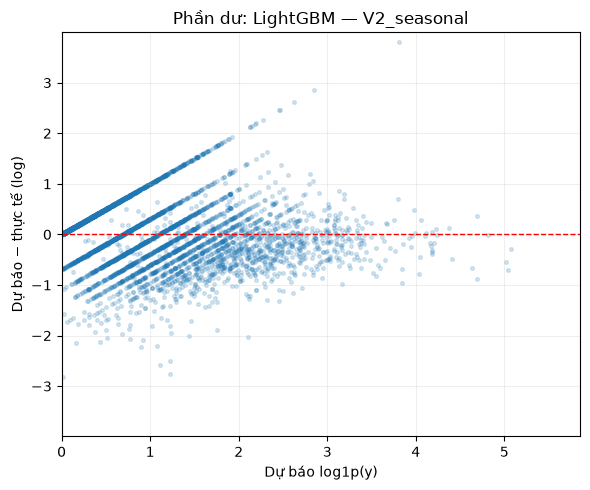

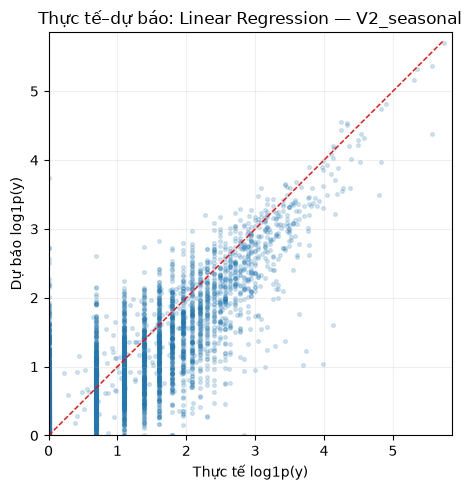

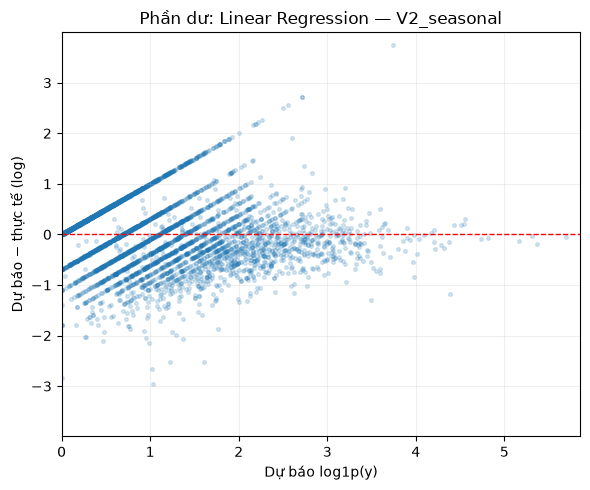

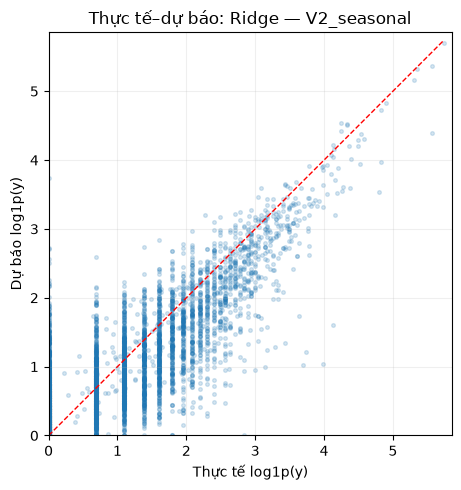

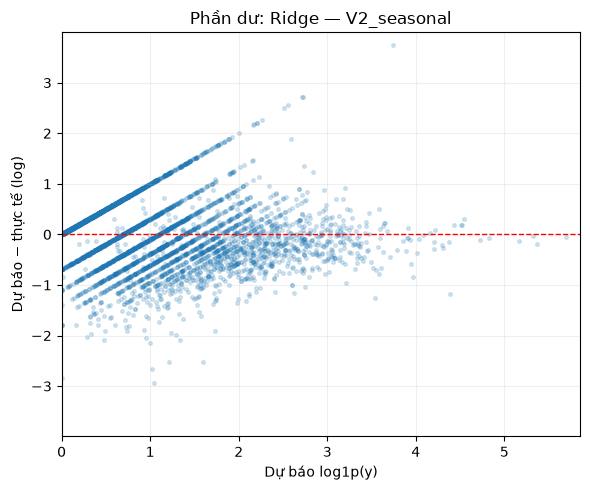

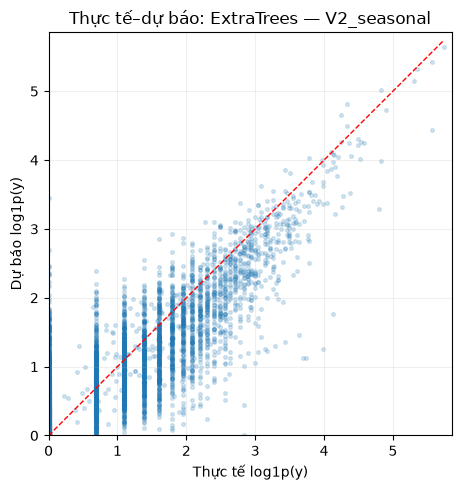

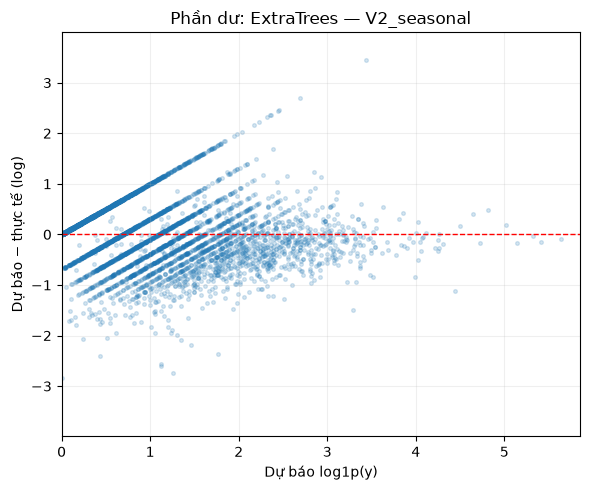

In [30]:
# So sánh điểm của các mô hình đã chạy với B2c.
visual_names={'safe':'LightGBM','linear_safe':'Linear Regression','ridge_safe':'Ridge','extratrees_safe':'ExtraTrees'}
vis=summary[summary.experiment.isin(visual_names)].copy()
vis['model_name']=vis.experiment.map(visual_names)
bar_data=vis.pivot(index='model_name',columns='fold',values='model')
base=summary.groupby('fold')['B2c_mean28'].first()
bar_data.loc['B2c mean28']=base.reindex(bar_data.columns)
bar_data=bar_data.reindex([x for x in ['B2c mean28','Linear Regression','Ridge','ExtraTrees','LightGBM'] if x in bar_data.index])
ax=bar_data.plot.bar(figsize=(10,5),rot=0,width=.75)
ax.set(title='NWRMSLE — toàn bộ validation',xlabel='',ylabel='NWRMSLE (thấp hơn tốt hơn)')
ax.grid(axis='y',alpha=.25)
for container in ax.containers:
    ax.bar_label(container,fmt='%.4f',fontsize=8,padding=3)
ax.margins(y=.15)
ax.figure.tight_layout()
ax.figure.savefig(REPORT_DIR/'05_model_comparison.png',dpi=150,bbox_inches='tight')
plt.show()

# 2. Lấy mẫu đều theo dòng bằng random priority; chỉ giữ tối đa n dòng trong RAM.
def sample_prediction_file(path,n=5000,seed=42):
    rng=np.random.default_rng(seed)
    kept=pd.DataFrame()
    for batch in pq.ParquetFile(path).iter_batches(batch_size=8192,columns=['y_log','pred_log']):
        part=batch.to_pandas()
        part['_priority']=rng.random(len(part))
        kept=pd.concat([kept,part],ignore_index=True).nsmallest(n,'_priority')
    return kept.drop(columns='_priority')

for fold in folds:
    available=[(exp,name,PRED_DIR/f"{fold['fold']}_{exp}.parquet")
               for exp,name in visual_names.items()
               if exp in set(vis.loc[vis.fold == fold['fold'], 'experiment'])
               and (PRED_DIR/f"{fold['fold']}_{exp}.parquet").is_file()]
    if not available:
        print(f"{fold['fold']}: chưa có file dự báo để vẽ scatter.")
        continue
    samples=[sample_prediction_file(path,seed=SEED) for _,_,path in available]
    # Chỉ so sánh trên cùng các nhãn mẫu; khác nhau thì dừng để kiểm tra nguồn file.
    for sample in samples[1:]:
        assert np.array_equal(sample.y_log.to_numpy(),samples[0].y_log.to_numpy()), 'Mẫu giữa model không khớp.'
    upper=max(float(max(s.y_log.max(),s.pred_log.max())) for s in samples)
    upper=max(upper,.1)
    residual_limit=max(float(np.abs(s.pred_log-s.y_log).max()) for s in samples)
    residual_limit=max(residual_limit,.1)
    # Hình 1: thực tế và dự báo — riêng từng mô hình trong fold.
    for (exp,name,path),s in zip(available,samples):
        fig,ax=plt.subplots(figsize=(6,5))
        ax.scatter(s.y_log,s.pred_log,s=7,alpha=.18,rasterized=True)
        ax.plot([0,upper],[0,upper],'r--',linewidth=1)
        ax.set(title=f'Thực tế–dự báo: {name} — {fold["fold"]}',
               xlabel='Thực tế log1p(y)',ylabel='Dự báo log1p(y)',
               xlim=(0,upper*1.02),ylim=(0,upper*1.02))
        ax.set_aspect('equal',adjustable='box')
        ax.grid(alpha=.2); fig.tight_layout()
        fig.savefig(REPORT_DIR/f"05_scatter_{fold['fold']}_{exp}.png",dpi=150,bbox_inches='tight')
        plt.show()

        # Hình 2: phần dư — cũng là một hình độc lập cho từng mô hình.
        residual=s.pred_log-s.y_log
        fig,ax=plt.subplots(figsize=(6,5))
        ax.scatter(s.pred_log,residual,s=7,alpha=.18,rasterized=True)
        ax.axhline(0,color='red',linestyle='--',linewidth=1)
        ax.set(title=f'Phần dư: {name} — {fold["fold"]}',
               xlabel='Dự báo log1p(y)',ylabel='Dự báo − thực tế (log)',
               xlim=(0,upper*1.02),ylim=(-residual_limit*1.05,residual_limit*1.05))
        ax.grid(alpha=.2); fig.tight_layout()
        fig.savefig(REPORT_DIR/f"05_residual_{fold['fold']}_{exp}.png",dpi=150,bbox_inches='tight')
        plt.show()


### Đánh giá các biểu đồ

**1. Biểu đồ cột NWRMSLE:** So sánh B2c mean28, Linear Regression, Ridge, ExtraTrees và LightGBM trên V1/V2. Cột thấp hơn biểu thị lỗi thấp hơn. Đọc nhãn số trên cột và bảng `comparison.csv`; không khẳng định mô hình nào tốt nhất trước khi notebook chạy đủ cả bốn phương án.

**2. Scatter plot thực tế–dự báo:** Mỗi điểm là một dòng validation được lấy mẫu để hiển thị. Điểm càng gần đường chéo thì dự báo càng sát thực tế. Các điểm chồng dày ở vùng thấp là bình thường với dữ liệu bán hàng nhiều giá trị 0/thấp.

**3. Residual plot:** Phần dư = dự báo − thực tế. Điểm phân bố quanh đường 0 là dấu hiệu ít lệch hệ thống hơn; hình dạng dải có thể xuất hiện vì nhãn bán hàng rời rạc sau phép `log1p`. So sánh các mô hình trên cùng fold và cùng mẫu, không chỉ nhìn một hình riêng lẻ.

**4. Sai số theo horizon và feature importance:** Sai số theo `h` cho biết độ khó thay đổi theo số ngày dự báo. Feature importance chỉ mô tả mức sử dụng feature của LightGBM, không chứng minh quan hệ nhân quả.


### Kết luận

Notebook đối chiếu baseline B2c mean28 với Linear Regression, Ridge, ExtraTrees và LightGBM bằng NWRMSLE có trọng số trên hai fold thời gian. Kết luận cuối cùng phải căn cứ vào `comparison.csv` và các biểu đồ sau khi chạy notebook với dữ liệu của dự án. Không suy rộng điểm validation thành chất lượng trên toàn bộ test; chất lượng nhóm cold-start vẫn cần đánh giá riêng.


## 8. Fit model cuối

Fit lại safe bằng các mốc train có nhãn kết thúc trước hoặc tại mốc test. Số vòng lấy trung vị từ hai lần chọn bằng kiểm định nội bộ.

Cặp có lịch sử dùng safe. Cặp mới dùng item, family–store, class, store, rồi hằng số. Kiểm tra dự báo hữu hạn không thay cho đánh giá chất lượng cặp mới.


In [31]:
def routed_prediction(model,d,features,constant_log):
    status=d.pair_status.to_numpy()
    assert np.isin(status,[0,1,2,3]).all()
    pred=np.full(len(d),np.nan,dtype=np.float64)
    known=status<2
    if known.any():pred[known]=np.maximum(model.predict(matrix(d.loc[known],features),num_threads=2),0)
    for col in ['item_mean_28','family_store_mean_28','class_mean_28','store_mean_28']:
        a=d[col].to_numpy(dtype=np.float64)
        use=~known & ~np.isfinite(pred) & np.isfinite(a)
        pred[use]=a[use]
    pred[~np.isfinite(pred)]=constant_log
    return np.maximum(pred,0)

final_info={'created':False,'cold_start_quality_validated':False}
if REFIT_FINAL_SAFE:
    cut=pd.Timestamp(config['test_origin']);tr=eligible_train(cut);features=feature_sets['safe']
    rounds=max(1,int(np.median([r['best_iteration'] for r in runs if r['experiment']=='safe'])))
    x,y,w=load_sample(tr,features,MAX_TRAIN_ROWS,SEED+int(cut.strftime('%Y%m%d')),cut)
    constant=float(np.average(y,weights=w));n=len(y)
    ds=dataset_for(x,y,w,features)
    final_model=lgb.train(PARAMS,ds,num_boost_round=rounds)
    final_model.free_dataset();del ds,x,y,w;gc.collect()
    final_path=MODEL_DIR/'safe_final.txt';final_model.save_model(str(final_path))
    # Kiểm tra toàn bộ test theo batch; không lưu dự báo/submission ở 05.
    test=manifest[manifest.role=='test'];assert len(test)==1
    counts=defaultdict(int)
    cols=list(dict.fromkeys(features+['pair_status','item_mean_28','family_store_mean_28','class_mean_28','store_mean_28']))
    for d in iter_frames(test.path,cols):
        p=routed_prediction(final_model,d,features,constant)
        assert np.isfinite(p).all() and (p>=0).all()
        for s,k in d.pair_status.value_counts().items():counts[int(s)]+=int(k)
    assert sum(counts.values())==int(test.rows.sum())
    final_info=dict(created=True,model_path=str(final_path.relative_to(ROOT)),features=features,
        categorical_features=[c for c in CATEGORICAL if c in features],num_boost_round=rounds,
        sampled_train_rows=n,constant_log=constant,test_rows_by_status=dict(counts),
        finite_predictions_check='PASS',cold_start_quality_validated=False,
        routing='status 0/1 -> safe; 2/3 -> item, family_store, class, store, constant',
        prediction_scale='log1p; actual units = expm1(max(pred_log, 0))')
    del final_model;gc.collect()
    print('Đã lưu model cuối; dự báo test hữu hạn. Chưa có điểm test/cold-start.')


Đã lưu model cuối; dự báo test hữu hạn. Chưa có điểm test/cold-start.


## 9. Lưu báo cáo

Mỗi lần chạy lưu model, bảng điểm và báo cáo trong thư mục riêng theo `run_id`. `reports/05_latest_run.json` được cập nhật khi chạy xong.


In [32]:
report=dict(created_at_utc=datetime.now(timezone.utc).isoformat(),run_id=RUN_ID,
    versions=dict(python=platform.python_version(),lightgbm=lgb.__version__,numpy=np.__version__,
                  pandas=pd.__version__,pyarrow=pa.__version__),
    sklearn_version=__import__('sklearn').__version__,
    source_config_sha256=digest(CONFIG_PATH),source_manifest_sha256=digest(MANIFEST_PATH),
    baseline_report_sha256=digest(BASELINE_REPORT),params=PARAMS,
    settings=dict(seed=SEED,max_train_rows=MAX_TRAIN_ROWS,max_inner_valid_rows=MAX_INNER_VALID_ROWS,
        batch_size=BATCH_SIZE,train_origin_min=TRAIN_ORIGIN_MIN,experiments=RUN_EXPERIMENTS),
    comparison=summary.to_dict(orient='records'),training_runs=runs,final_model=final_info,
    safe_beats_baseline_both_folds=bool((summary[summary.experiment=='safe'].improvement>0).all()),
    limits=['Training dùng mẫu giới hạn, không phải toàn bộ dữ liệu 03.',
            'V1/V2 đã được xem để so sánh, không phải final holdout độc lập.',
            'Cold-start chưa có đánh giá chất lượng.',
            'Khuyến mãi tương lai có rủi ro do cơ chế quan sát dòng bán.',
            'Chưa thử thay đổi quy ước ngày vắng = 0.'])
report_path=REPORT_DIR/'05_model_training_report.json'
report_path.write_text(json.dumps(report,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
latest=dict(run_id=RUN_ID,report=str(report_path.relative_to(ROOT)),
            models=str(MODEL_DIR.relative_to(ROOT)),predictions=str(PRED_DIR.relative_to(ROOT)))
(ROOT/'reports/05_latest_run.json').write_text(json.dumps(latest,indent=2),encoding='utf-8')
print('Hoàn thành. Báo cáo:',report_path.relative_to(ROOT))
print('Gửi notebook có output và 05_model_training_report.json để đánh giá trước bước 06.')


Hoàn thành. Báo cáo: reports\05_runs\20261029_225329\05_model_training_report.json
Gửi notebook có output và 05_model_training_report.json để đánh giá trước bước 06.


## 10. Kết quả và việc còn lại

- [x] Pipeline LightGBM và baseline B2c mean28.
- [x] Bổ sung Linear Regression, Ridge và ExtraTrees trên feature `safe`, cùng fold và metric NWRMSLE.
- [x] Lưu dự báo validation riêng theo mô hình để vẽ và so sánh từng hình.
- [ ] Chạy lại notebook từ đầu trong môi trường có dữ liệu 03/04 để cập nhật điểm số thật.
- [ ] Đánh giá sâu theo nhóm và kiểm tra dự báo ở notebook 06.
- [ ] Kiểm chứng chất lượng cặp mới/cold-start.

Chưa có cơ sở kết luận mô hình tốt nhất hoặc chất lượng toàn bộ test cho đến khi chạy đủ pipeline và kiểm tra báo cáo sinh ra.
